In [93]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

In [2]:
milk = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Datasets\milk.csv",index_col=0)
milk.sample(5)

,water,protein,fat,lactose,ash
Animal,,,,,
REINDEER,64.8,10.7,20.3,2.5,1.40
FOX,81.6,6.6,5.9,4.9,0.93
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
CAMEL,87.7,3.5,3.4,4.8,0.71
DONKEY,90.3,1.7,1.4,6.2,0.40


In [3]:
scaler = StandardScaler().set_output(transform='pandas')
df_scal = scaler.fit_transform(milk)
df_scal

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,0.948806,-1.009291,-0.903208,1.542217,-1.037554
ORANGUTAN,0.821407,-1.344603,-0.660619,1.040773,-1.259945
MONKEY,0.813445,-1.121062,-0.738247,1.263637,-1.381249
DONKEY,0.964731,-1.260775,-0.864394,1.152205,-0.936467
HIPPO,0.972694,-1.568145,-0.563583,0.149319,-1.542988
CAMEL,0.757707,-0.757806,-0.670322,0.372182,-0.309730
BISON,0.694008,-0.394551,-0.835283,0.873626,0.074400
BUFFALO,0.311810,-0.087181,-0.233662,0.316466,-0.168208
GUINEA PIG,0.295885,0.331959,-0.301587,-0.797852,-0.026687


In [4]:
prcomp = PCA().set_output(transform='pandas')
df_pca = prcomp.fit_transform(df_scal)
df_pca

,pca0,pca1,pca2,pca3,pca4
Animal,,,,,
HORSE,2.435175,-0.231478,0.330150,0.307664,0.048184
ORANGUTAN,2.258736,-0.693148,0.029035,-0.081057,-0.000532
MONKEY,2.335861,-0.663328,0.101257,0.247997,0.010109
DONKEY,2.318677,-0.273815,0.109881,-0.092873,-0.006769
HIPPO,2.060294,-1.019199,-0.762436,-0.510091,0.029382
CAMEL,1.301536,0.137303,-0.198742,-0.282160,-0.014668
BISON,1.282742,0.622667,0.253785,0.065148,-0.044486
BUFFALO,0.505068,0.088235,0.008383,0.133774,0.083806
GUINEA PIG,-0.255502,0.287373,-0.881857,-0.013100,-0.016484


In [5]:
df_pca.shape , df_scal.shape

((25, 5), (25, 5))

In [6]:
df_pca.var()

pca0    4.040412
pca1    0.924372
pca2    0.134291
pca3    0.102689
pca4    0.006570
dtype: float64

In [7]:
sigma = df_scal.cov()
values, vector = np.linalg.eig(sigma)
print('Eigen Values :-',values)
print('Eigen Vector :-',vector)

Eigen Values :- [4.0404117 +0.j 0.92437238+0.j 0.00656977+0.j 0.13429088+0.j
 0.1026886 +0.j]
Eigen Vector :- [[-0.47294379+0.j  0.35285509+0.j -0.70967042+0.j  0.36921298+0.j
   0.10893632+0.j]
 [ 0.46657047+0.j  0.32094099+0.j -0.1930657 +0.j  0.15196177+0.j
  -0.78672876+0.j]
 [ 0.44868269+0.j -0.47603724+0.j -0.66831106+0.j -0.30699163+0.j
   0.17660367+0.j]
 [-0.48289116+0.j  0.05951482+0.j -0.11159049+0.j -0.77642589+0.j
  -0.38468756+0.j]
 [ 0.35232959+0.j  0.73643513+0.j  0.00118661+0.j -0.378825  +0.j
   0.43590982+0.j]]


In [8]:
prcomp.explained_variance_

array([4.0404117 , 0.92437238, 0.13429088, 0.1026886 , 0.00656977])

In [9]:
total_variation = df_pca.var().sum()  # Summation of all variances of each pca component
total_variation

np.float64(5.208333333333338)

In [10]:
df_pca.var()/total_variation

pca0    0.775759
pca1    0.177479
pca2    0.025784
pca3    0.019716
pca4    0.001261
dtype: float64

In [11]:
prcomp.explained_variance_ratio_

array([0.77575905, 0.1774795 , 0.02578385, 0.01971621, 0.0012614 ])

In [12]:
prcomp.explained_variance_ratio_ * 100

array([77.57590469, 17.74794969,  2.57838496,  1.97162103,  0.12613963])

In [13]:
np.cumsum(prcomp.explained_variance_ratio_ * 100)

array([ 77.57590469,  95.32385438,  97.90223934,  99.87386037,
       100.        ])

In [14]:
df_pca[['pca0','pca1']]    # Both component gives 95 % information about data

,pca0,pca1
Animal,,
HORSE,2.435175,-0.231478
ORANGUTAN,2.258736,-0.693148
MONKEY,2.335861,-0.663328
DONKEY,2.318677,-0.273815
HIPPO,2.060294,-1.019199
CAMEL,1.301536,0.137303
BISON,1.282742,0.622667
BUFFALO,0.505068,0.088235
GUINEA PIG,-0.255502,0.287373


# Exercise

In [15]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Wisconsin\BreastCancer.csv",index_col=0)
df.sample(5)

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
1253505,2,3,1,1,5,1,1,1,1,Benign
810104,1,1,1,1,2,1,3,1,1,Benign
1168278,3,1,1,1,2,1,2,1,1,Benign
385103,1,1,1,1,2,1,3,1,1,Benign
560680,3,1,2,1,2,1,2,1,1,Benign


In [16]:
X , y = df.drop('Class',axis=1) , df['Class']
X_scal = scaler.fit_transform(X)

In [17]:
X_pca = prcomp.fit_transform(X_scal)
X_pca

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8
Code,,,,,,,,,
61634,-0.661561,-0.168216,0.583962,-0.439347,-0.230526,0.130653,-0.097528,0.541727,0.328081
63375,2.178759,-0.693348,0.432389,1.192376,-1.074153,-0.442691,-0.702441,-1.787781,-0.244667
76389,1.404956,-1.364750,1.761714,0.878367,0.013219,-0.517801,0.835375,0.408381,-0.565653
95719,6.073098,1.994961,-1.081435,0.237234,-0.141189,0.019790,-0.355352,0.444035,-0.062628
128059,-1.237518,-0.370332,-0.823064,0.473932,-0.127604,-1.151372,0.508269,-0.344131,0.029906
...,...,...,...,...,...,...,...,...,...
1369821,6.473443,1.285709,0.048059,0.936819,-1.446932,0.152226,0.731058,0.235807,-0.042668
1371026,4.097345,-0.215083,-1.078721,0.912918,0.027151,0.599090,-0.276698,1.705969,0.099999
1371920,-1.351669,-0.095164,0.536224,-0.120275,-0.359013,0.101649,0.178219,-0.452815,0.002252


In [18]:
prcomp.explained_variance_ratio_*100

array([65.45437483,  8.62625123,  5.98724547,  5.13612665,  4.21920122,
        3.39206535,  3.28441735,  2.91485025,  0.98546764])

In [19]:
np.cumsum(prcomp.explained_variance_ratio_*100)

array([ 65.45437483,  74.08062606,  80.06787153,  85.20399818,
        89.42319941,  92.81526476,  96.09968211,  99.01453236,
       100.        ])

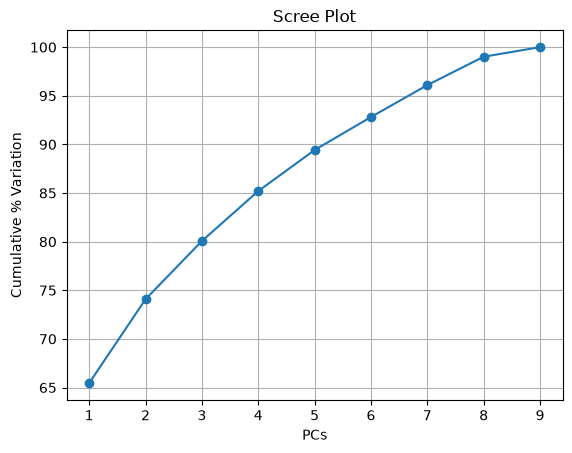

In [20]:
import matplotlib.pyplot as plt
# plt.scatter(range(1,10),np.cumsum(prcomp.explained_variance_ratio_*100))
# plt.plot(range(1,10),np.cumsum(prcomp.explained_variance_ratio_*100))
plt.plot(range(1,10),np.cumsum(prcomp.explained_variance_ratio_*100),marker='o')
plt.title('Scree Plot')
plt.xlabel('PCs')
plt.ylabel('Cumulative % Variation')
plt.grid(True)
plt.show()

In [21]:
df_pca = pd.concat([X_pca.iloc[:,:2],y],axis=1)
df_pca

,pca0,pca1,Class
Code,,,
61634,-0.661561,-0.168216,Benign
63375,2.178759,-0.693348,Malignant
76389,1.404956,-1.364750,Malignant
95719,6.073098,1.994961,Malignant
128059,-1.237518,-0.370332,Benign
...,...,...,...
1369821,6.473443,1.285709,Malignant
1371026,4.097345,-0.215083,Malignant
1371920,-1.351669,-0.095164,Benign


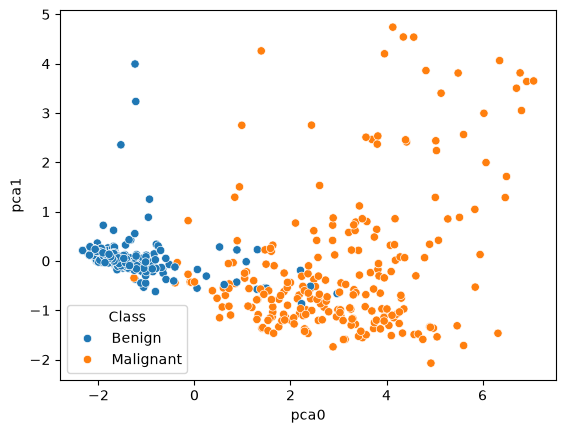

In [22]:
import seaborn as sns
sns.scatterplot(x=df_pca['pca0'],y=df_pca['pca1'],hue=df['Class'])
plt.show()

### SVM

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.svm import SVC

### Without PCA

In [24]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)
svc = SVC(kernel='linear')
svc.fit(X_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [25]:
y_pred = svc.predict(X_test)
f1_score(y_test,y_pred,pos_label='Malignant')

0.9324324324324325

### With PCA
Using Pipeline

In [26]:
from sklearn.pipeline import Pipeline
prcomp = PCA()   # take all components default component == number of feature
scaler = StandardScaler()
svm = SVC()

pipe = Pipeline([('SCL',scaler),('PCA',prcomp),('SVM',svm)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label='Malignant')

0.9395973154362416

### PCA(n_components=n) 
specifiy n number of component for pca

In [27]:
prcomp = PCA(n_components=5) 
scaler = StandardScaler()
svm = SVC(kernel='linear')

pipe = Pipeline([('SCL',scaler),('PCA',prcomp),('SVM',svm)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label='Malignant')

0.9530201342281879

# PCA -> Outside Scikit learn

In [28]:
from pca import pca

In [29]:
model = pca(normalize=True)
results = model.fit_transform(milk,row_labels=milk.index)

[21-10-2026 11:44:14] [pca.pca] [INFO] Extracting column labels from dataframe.
[21-10-2026 11:44:14] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[21-10-2026 11:44:14] [pca.pca] [INFO] PCA reduction performed to capture at least 95.0% explained variance using 5 columns of the input data.
[21-10-2026 11:44:14] [pca.pca] [INFO] Fit using PCA.
[21-10-2026 11:44:14] [pca.pca] [INFO] Compute loadings and PCs.
[21-10-2026 11:44:14] [pca.pca] [INFO] Compute explained variance.
[21-10-2026 11:44:14] [pca.pca] [INFO] The top 2 principal component(s) explains >= 95.00% of the explained variance.
[21-10-2026 11:44:14] [pca.pca] [INFO] The PCA reduction is performed on 5 variables (columns) of the input dataframe.
[21-10-2026 11:44:14] [pca.pca] [INFO] Fit using PCA.
[21-10-2026 11:44:14] [pca.pca] [INFO] Compute loadings and PCs.
[21-10-2026 11:44:14] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[2]
[21-10-20

[21-10-2026 11:44:14] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[21-10-2026 11:44:14] [scatterd.scatterd] [INFO] Create scatterplot


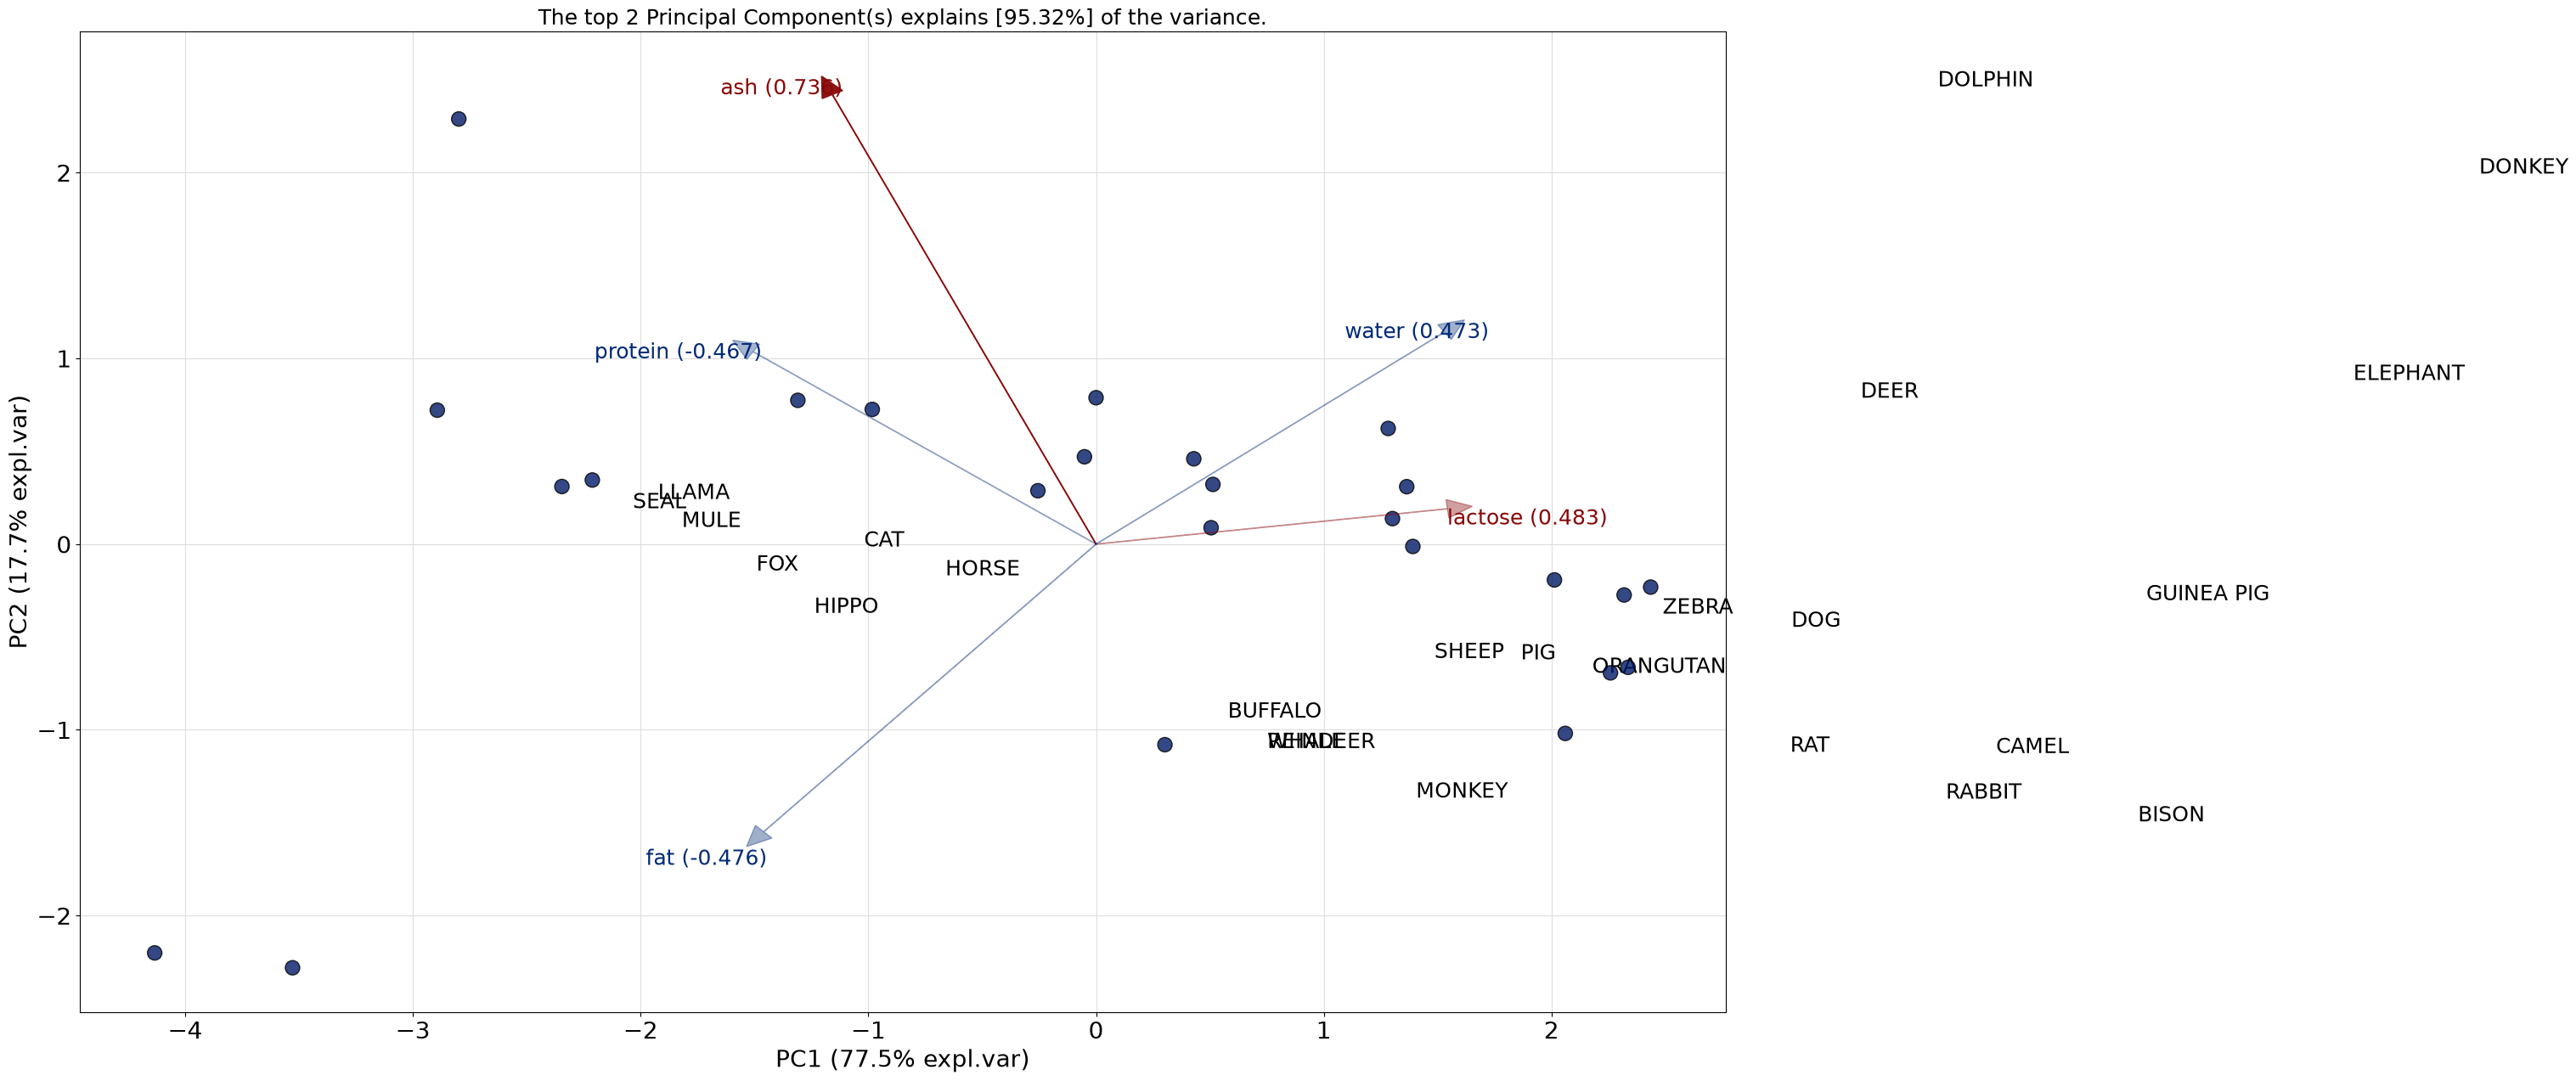

In [30]:
model.biplot()
for i in range(len(milk)):
    plt.text(df_pca['pca0'].iloc[i],df_pca['pca1'].iloc[i],milk.index[i]) # df_pca is PCA df from sklearn which we have created earlier 
plt.show()

# Exercise

In [32]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Datasets\nutrient.csv",index_col=0)
df.sample(5)

,energy,protein,fat,calcium,iron
Food_Item,,,,,
CHICKEN CANNED,170,25,7,12,1.5
BEEF TONGUE,205,18,14,7,2.5
PORK ROAST,340,19,29,9,2.5
CHICKEN BROILED,115,20,3,8,1.4
PERCH FRIED,195,16,11,14,1.3


In [46]:
model = pca(normalize=True)
results = model.fit_transform(df,row_labels=df.index)

# Using scikit learn PCA
df_scal = scaler.fit_transform(df)
prcomp = PCA().set_output(transform='pandas')
df_pca = prcomp.fit_transform(df_scal)

[21-10-2026 11:49:38] [pca.pca] [INFO] Extracting column labels from dataframe.
[21-10-2026 11:49:38] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[21-10-2026 11:49:38] [pca.pca] [INFO] PCA reduction performed to capture at least 95.0% explained variance using 5 columns of the input data.
[21-10-2026 11:49:38] [pca.pca] [INFO] Fit using PCA.
[21-10-2026 11:49:38] [pca.pca] [INFO] Compute loadings and PCs.
[21-10-2026 11:49:38] [pca.pca] [INFO] Compute explained variance.
[21-10-2026 11:49:38] [pca.pca] [INFO] The top 4 principal component(s) explains >= 95.00% of the explained variance.
[21-10-2026 11:49:38] [pca.pca] [INFO] The PCA reduction is performed on 5 variables (columns) of the input dataframe.
[21-10-2026 11:49:38] [pca.pca] [INFO] Fit using PCA.
[21-10-2026 11:49:38] [pca.pca] [INFO] Compute loadings and PCs.
[21-10-2026 11:49:38] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[4]
[21-10-20

[21-10-2026 11:48:43] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[21-10-2026 11:48:43] [scatterd.scatterd] [INFO] Create scatterplot


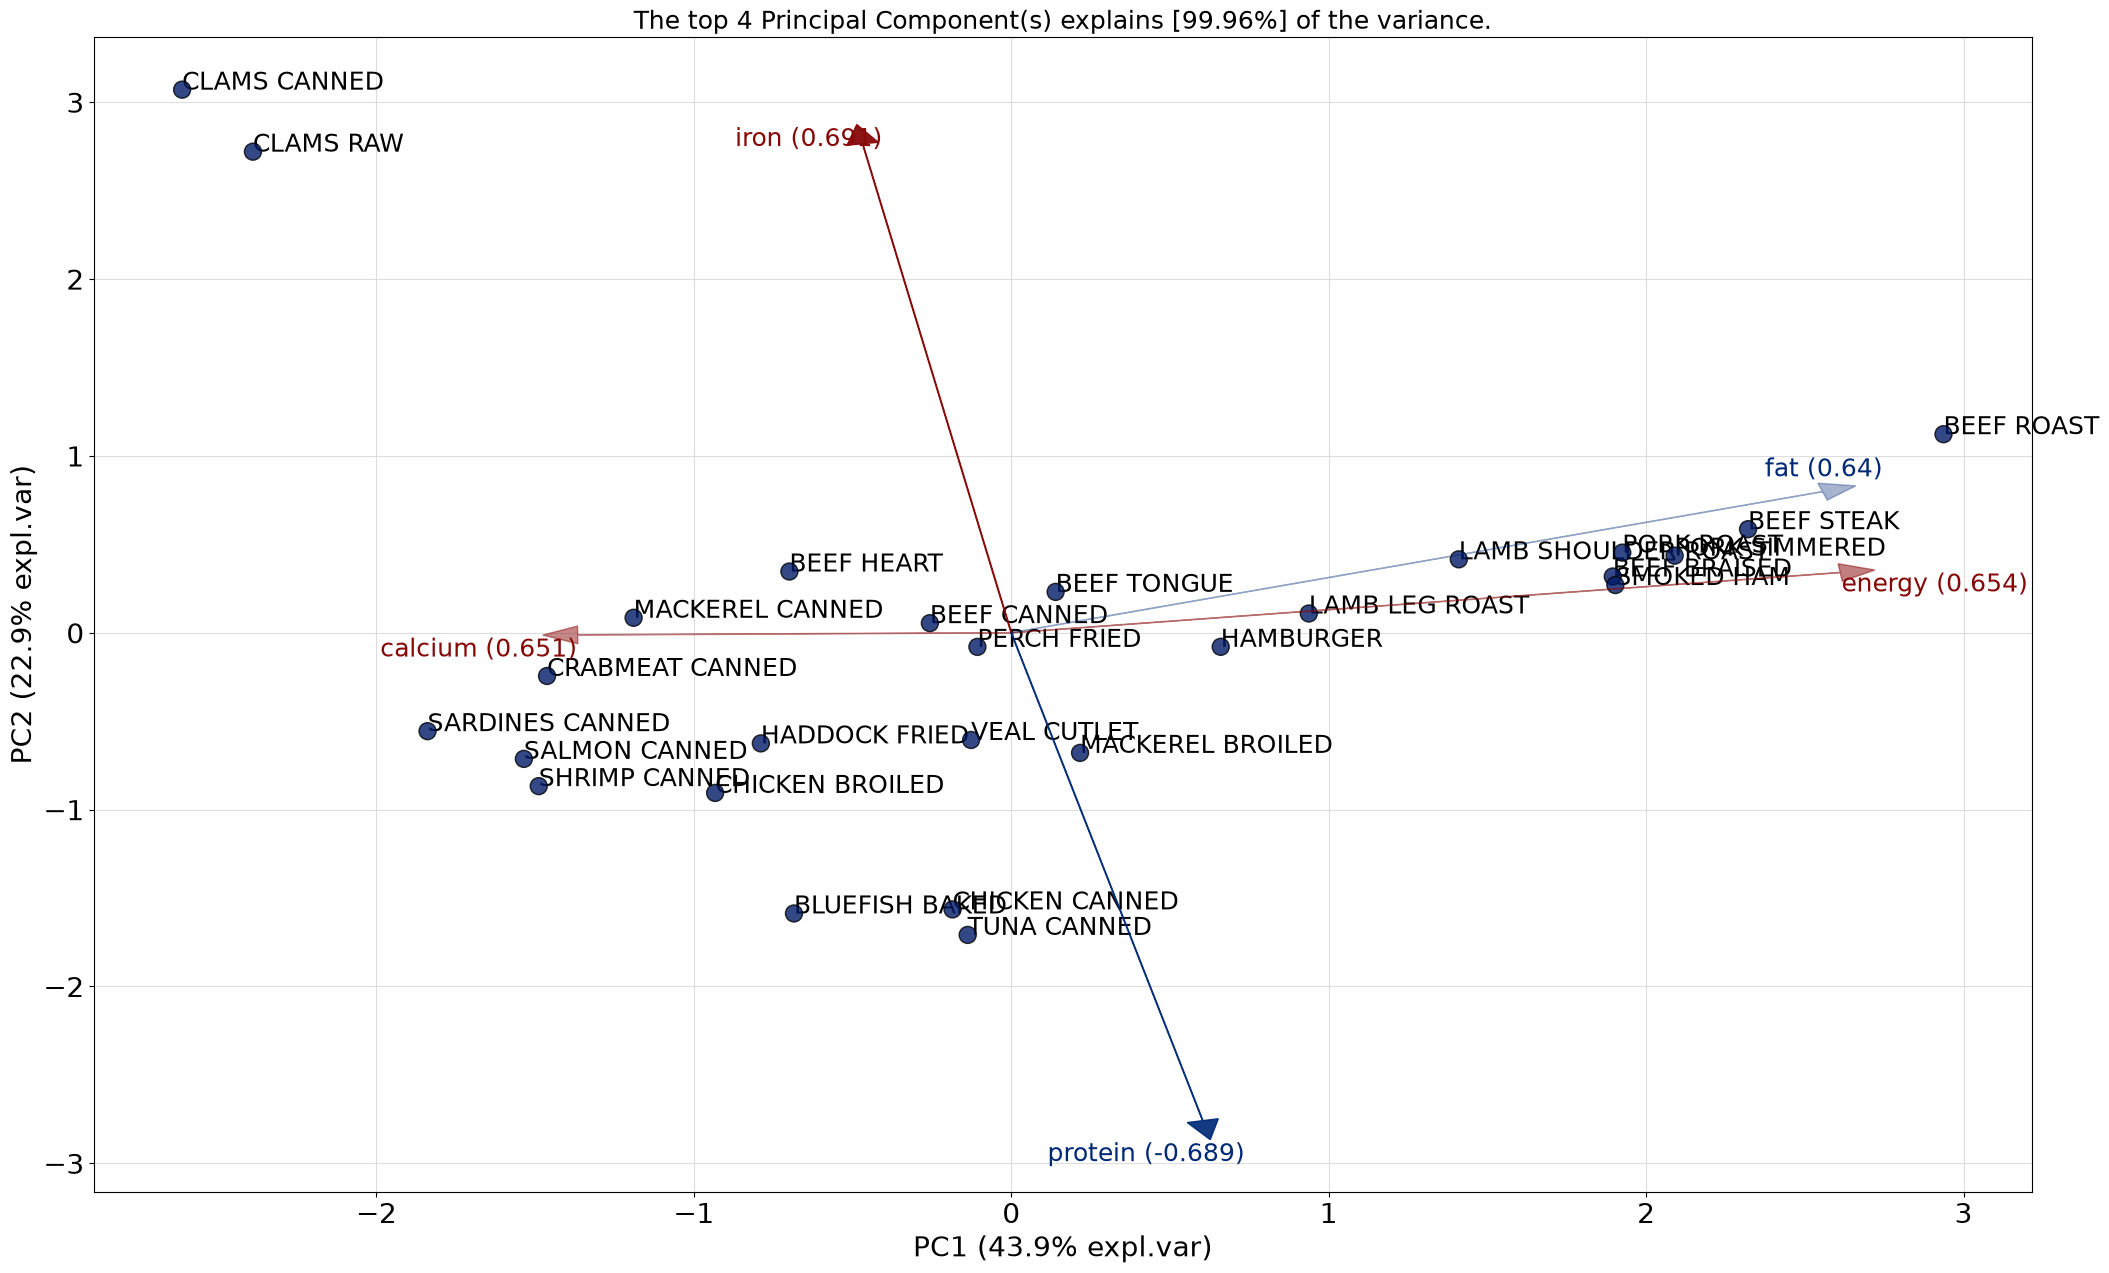

In [45]:
model.biplot()
for i in range(len(df)):
    plt.text(df_pca['pca0'].iloc[i] , df_pca['pca1'].iloc[i], df.index[i])
plt.show()

# Exercise

In [120]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Vehicle Silhouettes\Vehicle.csv")
df.sample(5)

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
719,104,53,101,199,65,11,213,31,24,168,216,667,221,72,12,12,187,198,saab
594,83,40,59,116,53,7,132,52,18,137,145,250,157,84,12,6,177,183,van
288,96,47,103,215,69,10,200,33,23,147,220,598,200,73,6,6,187,194,opel
372,97,47,87,164,64,9,156,43,20,149,173,359,182,68,1,13,192,202,van
187,98,45,76,166,60,7,157,42,20,148,184,371,186,69,13,10,190,196,opel


In [121]:
X , y = df.drop('Class',axis=1) , df['Class']

In [122]:
from sklearn.linear_model import LogisticRegression

prcomp = PCA().set_output(transform='pandas')
scaler = StandardScaler()
lr = LogisticRegression()

pipe = Pipeline([('SCL',scaler),('PCA',prcomp),('LR',lr)])

In [123]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold

kfold = StratifiedKFold(n_splits=5,random_state=26,shuffle=True)
param = {
    'LR__C' : np.linspace(0.001,5,10),
    'PCA__n_components':range(2,len(X.columns))
    # 'PCA__n_components':[0.6,0.7,0.75,0.8,0.85,0.9]
}
grid = GridSearchCV(pipe,param_grid=param,cv=kfold,scoring='neg_log_loss',n_jobs=-1)
grid.fit(X,y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'LR__C': array([1.0000...00000000e+00]), 'PCA__n_components': range(2, 18)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_log_loss'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbos

In [124]:
print('Best Params :-',grid.best_params_)
print('Best Score :-',grid.best_score_)

Best Params :- {'LR__C': np.float64(5.0), 'PCA__n_components': 17}
Best Score :- -0.42172030134986144


### Using SVM

In [129]:
svm = SVC(probability=True,random_state=26)  # Probability = True -> output class probabilities instead of just hard labels,
pipe = Pipeline([('SCL',scaler),('PCA',prcomp),('SVM',svm)])

kfold = StratifiedKFold(n_splits=5,random_state=26,shuffle=True)
param = {
    'SVM__C' : np.linspace(0.001,5,10),
    'SVM__kernel':['linear','poly'],
    'PCA__n_components':range(2,len(X.columns))
    # 'PCA__n_components':[0.6,0.7,0.75,0.8,0.85,0.9]
}
grid = GridSearchCV(pipe,param_grid=param,cv=kfold,scoring='neg_log_loss',n_jobs=-1) # to calculate neg_log_loss -> grid called pedict.proba()
# so we need output in probability bu SVC() gives output in hard labels that's why we used probability=True
grid.fit(X,y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=26))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'PCA__n_components': range(2, 18), 'SVM__C': array([1.0000...00000000e+00]), 'SVM__kernel': ['linear', 'poly']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_log_loss'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [130]:
print('Best Params :-',grid.best_params_)
print('Best Score :-',grid.best_score_)

Best Params :- {'PCA__n_components': 17, 'SVM__C': np.float64(5.0), 'SVM__kernel': 'linear'}
Best Score :- -0.41156779639233426
